<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 3 · Polygons — A Bulgarian November
### #30DayMapChallenge 2026 · ERA5 open data (ARCO-ERA5) · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment to show
> how approachable open weather data has become.

For **Day 3 (Polygons)**, Bulgaria's **28 _oblasti_** (provinces) are the polygons — shaded by
the climate that defines a Bulgarian November. Two maps from one dataset: a plain **choropleth**
of typical November rainfall, and a **bivariate** map pairing rainfall with temperature, so the
cold-and-wet southern mountains stand out against the mild-and-dry lowlands.

Built live from **ERA5** as cloud-native **Zarr** (ARCO-ERA5) — no downloads; 30 years of
reanalysis streamed straight from the cloud.

## Method

- **Polygons:** Bulgaria’s 28 provinces (*oblasti*), from Natural Earth admin-1 boundaries.
- **The field:** ERA5 reanalysis, the November **1991–2020** climate normal.
  - *Rainfall* — total precipitation summed over every 6-hourly step in November, averaged across the 30 years → a typical November total (mm).
  - *Temperature* — mean 2 m temperature over the same window (°C).
- **Zonal statistics:** each province takes the mean of the ERA5 grid cells whose centres fall inside it (nearest cell for provinces smaller than a grid box).
- **Bivariate:** rainfall and temperature are each split into **terciles**; the 3×3 combination gives each province one of nine colours (wetter → right, colder → up).
- Rivers (Danube, Iskar, Yantra, Tundzha, Arda, Maritsa) and the capital **Sofia ★** for orientation.

## Licence & attribution

**ERA5** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)** and is free to
use with attribution; **ARCO-ERA5** is a cloud-native copy hosted by Google. Province boundaries are
**Natural Earth** (public domain).

Attribute a map made from this data:
`Contains modified Copernicus Climate Change Service information [1991–2020]`  ·  `© ECMWF`

## Tools

Pure open-source Python — no API key, nothing to download:

| Tool | Role |
|---|---|
| [`xarray`](https://docs.xarray.dev) + [`zarr`](https://zarr.readthedocs.io) · [`gcsfs`](https://gcsfs.readthedocs.io) | open ARCO-ERA5 as cloud-native Zarr, stream only what’s needed |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`shapely`](https://shapely.readthedocs.io) | provinces, rivers, zonal geometry |
| [`matplotlib`](https://matplotlib.org) | the choropleth + bivariate render |

**Learn more:** [ARCO-ERA5](https://github.com/google-research/arco-era5)  ·  [ERA5 (Copernicus CDS)](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)  ·  [#30DayMapChallenge](https://30daymapchallenge.com/)

In [1]:
import os, time, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.image as mpimg
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union
from shapely.geometry import Point, box
from shapely.prepared import prep
warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

### Configuration

In [2]:
URL    = "gs://gcp-public-data-arco-era5/ar/1959-2022-6h-1440x721.zarr"  # ARCO-ERA5, 6-hourly 0.25°
YEARS  = (1991, 2020)                                       # WMO climate normal
BBOX   = dict(longitude=slice(22, 29), latitude=slice(44.8, 40.8))  # Bulgaria
EXTENT = [21.8, 29.2, 40.7, 44.6]
INK, MUT, RIV, AUTHOR = "#1d2230", "#6b7280", "#2c6fb3", "Emma Pidduck"

## Retrieve & compute

Open the archive as Zarr and pull **only** Bulgaria, **only** November, **only** 1991–2020 — the rest
never leaves the cloud. This streams ~3,600 six-hourly fields, so a live run takes a few minutes.

In [3]:
t0 = time.time()
ds = xr.open_zarr(URL, storage_options={"token": "anon"})
ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")
sub = ds[["total_precipitation_6hr", "2m_temperature"]].sel(**BBOX)
mask = (sub.time.dt.month == 11) & (sub.time.dt.year >= YEARS[0]) & (sub.time.dt.year <= YEARS[1])
sub = sub.sel(time=mask)
ny = YEARS[1] - YEARS[0] + 1
precip = (sub["total_precipitation_6hr"].sum("time") / ny * 1000).compute()  # mm per November
temp   = (sub["2m_temperature"].mean("time") - 273.15).compute()             # °C
print(f"streamed {sub.sizes['time']} six-hourly steps in {time.time()-t0:.0f}s")
print(f"precip {float(precip.min()):.0f}-{float(precip.max()):.0f} mm   temp {float(temp.min()):.1f}-{float(temp.max()):.1f} °C")

streamed 3600 six-hourly steps in 1440s
precip 39-107 mm   temp 2.3-13.0 °C


## Provinces, zonal statistics & rivers

In [4]:
fn = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_1_states_provinces")
provinces = [(r.attributes["name"], r.geometry) for r in shpreader.Reader(fn).records()
             if r.attributes.get("admin") == "Bulgaria"]
union = unary_union([g for _, g in provinces])

LO, LA = np.meshgrid(precip.longitude.values, precip.latitude.values)
Pg, Tg = precip.values, temp.values
flat = list(zip(LA.ravel(), LO.ravel(), Pg.ravel(), Tg.ravel()))

def zonal(geom):
    pg = prep(geom)
    ins = [(p, t) for (la, lo, p, t) in flat if pg.contains(Point(lo, la))]
    if ins:
        return float(np.mean([p for p, _ in ins])), float(np.mean([t for _, t in ins]))
    c = geom.centroid; k = int(np.argmin((LA - c.y) ** 2 + (LO - c.x) ** 2))
    return float(Pg.ravel()[k]), float(Tg.ravel()[k])

Z = {nm: zonal(g) for nm, g in provinces}
P = {nm: Z[nm][0] for nm in Z}
T = {nm: Z[nm][1] for nm in Z}

# rivers: detailed European set clipped to Bulgaria, plus the Danube border
reu = shpreader.natural_earth(resolution="10m", category="physical", name="rivers_europe")
RIVERS = [g.intersection(union.buffer(0.02)) for r in shpreader.Reader(reu).records()
          if (g := r.geometry) is not None and g.intersects(union)]
rb = shpreader.natural_earth(resolution="10m", category="physical", name="rivers_lake_centerlines")
BGbox = box(EXTENT[0], EXTENT[2], EXTENT[1], EXTENT[3])
DANUBE = [r.geometry.intersection(BGbox) for r in shpreader.Reader(rb).records()
          if r.attributes.get("name") == "Danube" and r.geometry and r.geometry.intersects(BGbox)]
print(f"{len(provinces)} provinces · {len(RIVERS)} river reaches")

28 provinces · 15 river reaches


### Shared map furniture (rivers, Sofia, labels, logo, footer)

In [5]:
proj = ccrs.AlbersEqualArea(central_longitude=25.3, central_latitude=42.7, standard_parallels=(41, 44))
halo = [pe.withStroke(linewidth=2.0, foreground="white")]
RLAB = {"Danube": (26.0, 43.96), "Maritsa": (25.15, 42.03), "Iskar": (23.95, 43.32),
        "Tundzha": (26.6, 42.28), "Arda": (25.2, 41.5), "Yantra": (25.62, 43.3)}

def province_label(nm):
    if nm == "Grad Sofiya": return None            # the star marks the capital
    return "Sofia Province" if nm == "Sofia" else nm

def draw_geo(ax, label_rivers=True):
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree()); ax.set_facecolor("#eef3f6")
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#dbe7ef", zorder=0)
    for g in RIVERS:
        ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=RIV, linewidth=0.9, alpha=0.85, zorder=5)
    for g in DANUBE:
        ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=RIV, linewidth=1.7, alpha=0.9, zorder=5)
    if label_rivers:
        for nm, (lo, la) in RLAB.items():
            ax.text(lo, la, nm, transform=ccrs.PlateCarree(), ha="center", va="center",
                    fontsize=7.5, style="italic", color=RIV, zorder=7, path_effects=halo)
    ax.plot(23.3219, 42.6977, marker="*", ms=19, mfc="#ffd23d", mec=INK, mew=1.1, transform=ccrs.PlateCarree(), zorder=8)
    ax.text(23.3219, 42.55, "Sofia", transform=ccrs.PlateCarree(), ha="center", va="top", fontsize=10, fontweight="bold", color=INK, zorder=8, path_effects=halo)
    ax.text(28.4, 42.95, "Black\nSea", transform=ccrs.PlateCarree(), ha="center", va="center", fontsize=10, style="italic", color="#5b7c91", zorder=3)

def add_logo(fig):
    p = "assets/ECMWF_Core_Logo_RGB.png"
    if os.path.exists(p):
        im = mpimg.imread(p); ar = im.shape[1] / im.shape[0]
        h = 0.055; w = h * ar * (fig.get_figheight() / fig.get_figwidth())
        a = fig.add_axes([0.93 - w, 0.02, w, h]); a.imshow(im); a.axis("off")

def add_footer(fig):
    fig.text(0.03, 0.052, "Data: ERA5 reanalysis (ECMWF) · Contains modified Copernicus Climate Change Service information (1991–2020) · boundaries: Natural Earth", color=MUT, fontsize=8.8)
    fig.text(0.03, 0.032, "© ECMWF / Copernicus · Licence: CC-BY-4.0 · Map: " + AUTHOR + " · #30DayMapChallenge 2026 · Day 3 · Polygons", color=MUT, fontsize=8.8)

## Map 1 — the choropleth: typical November rainfall

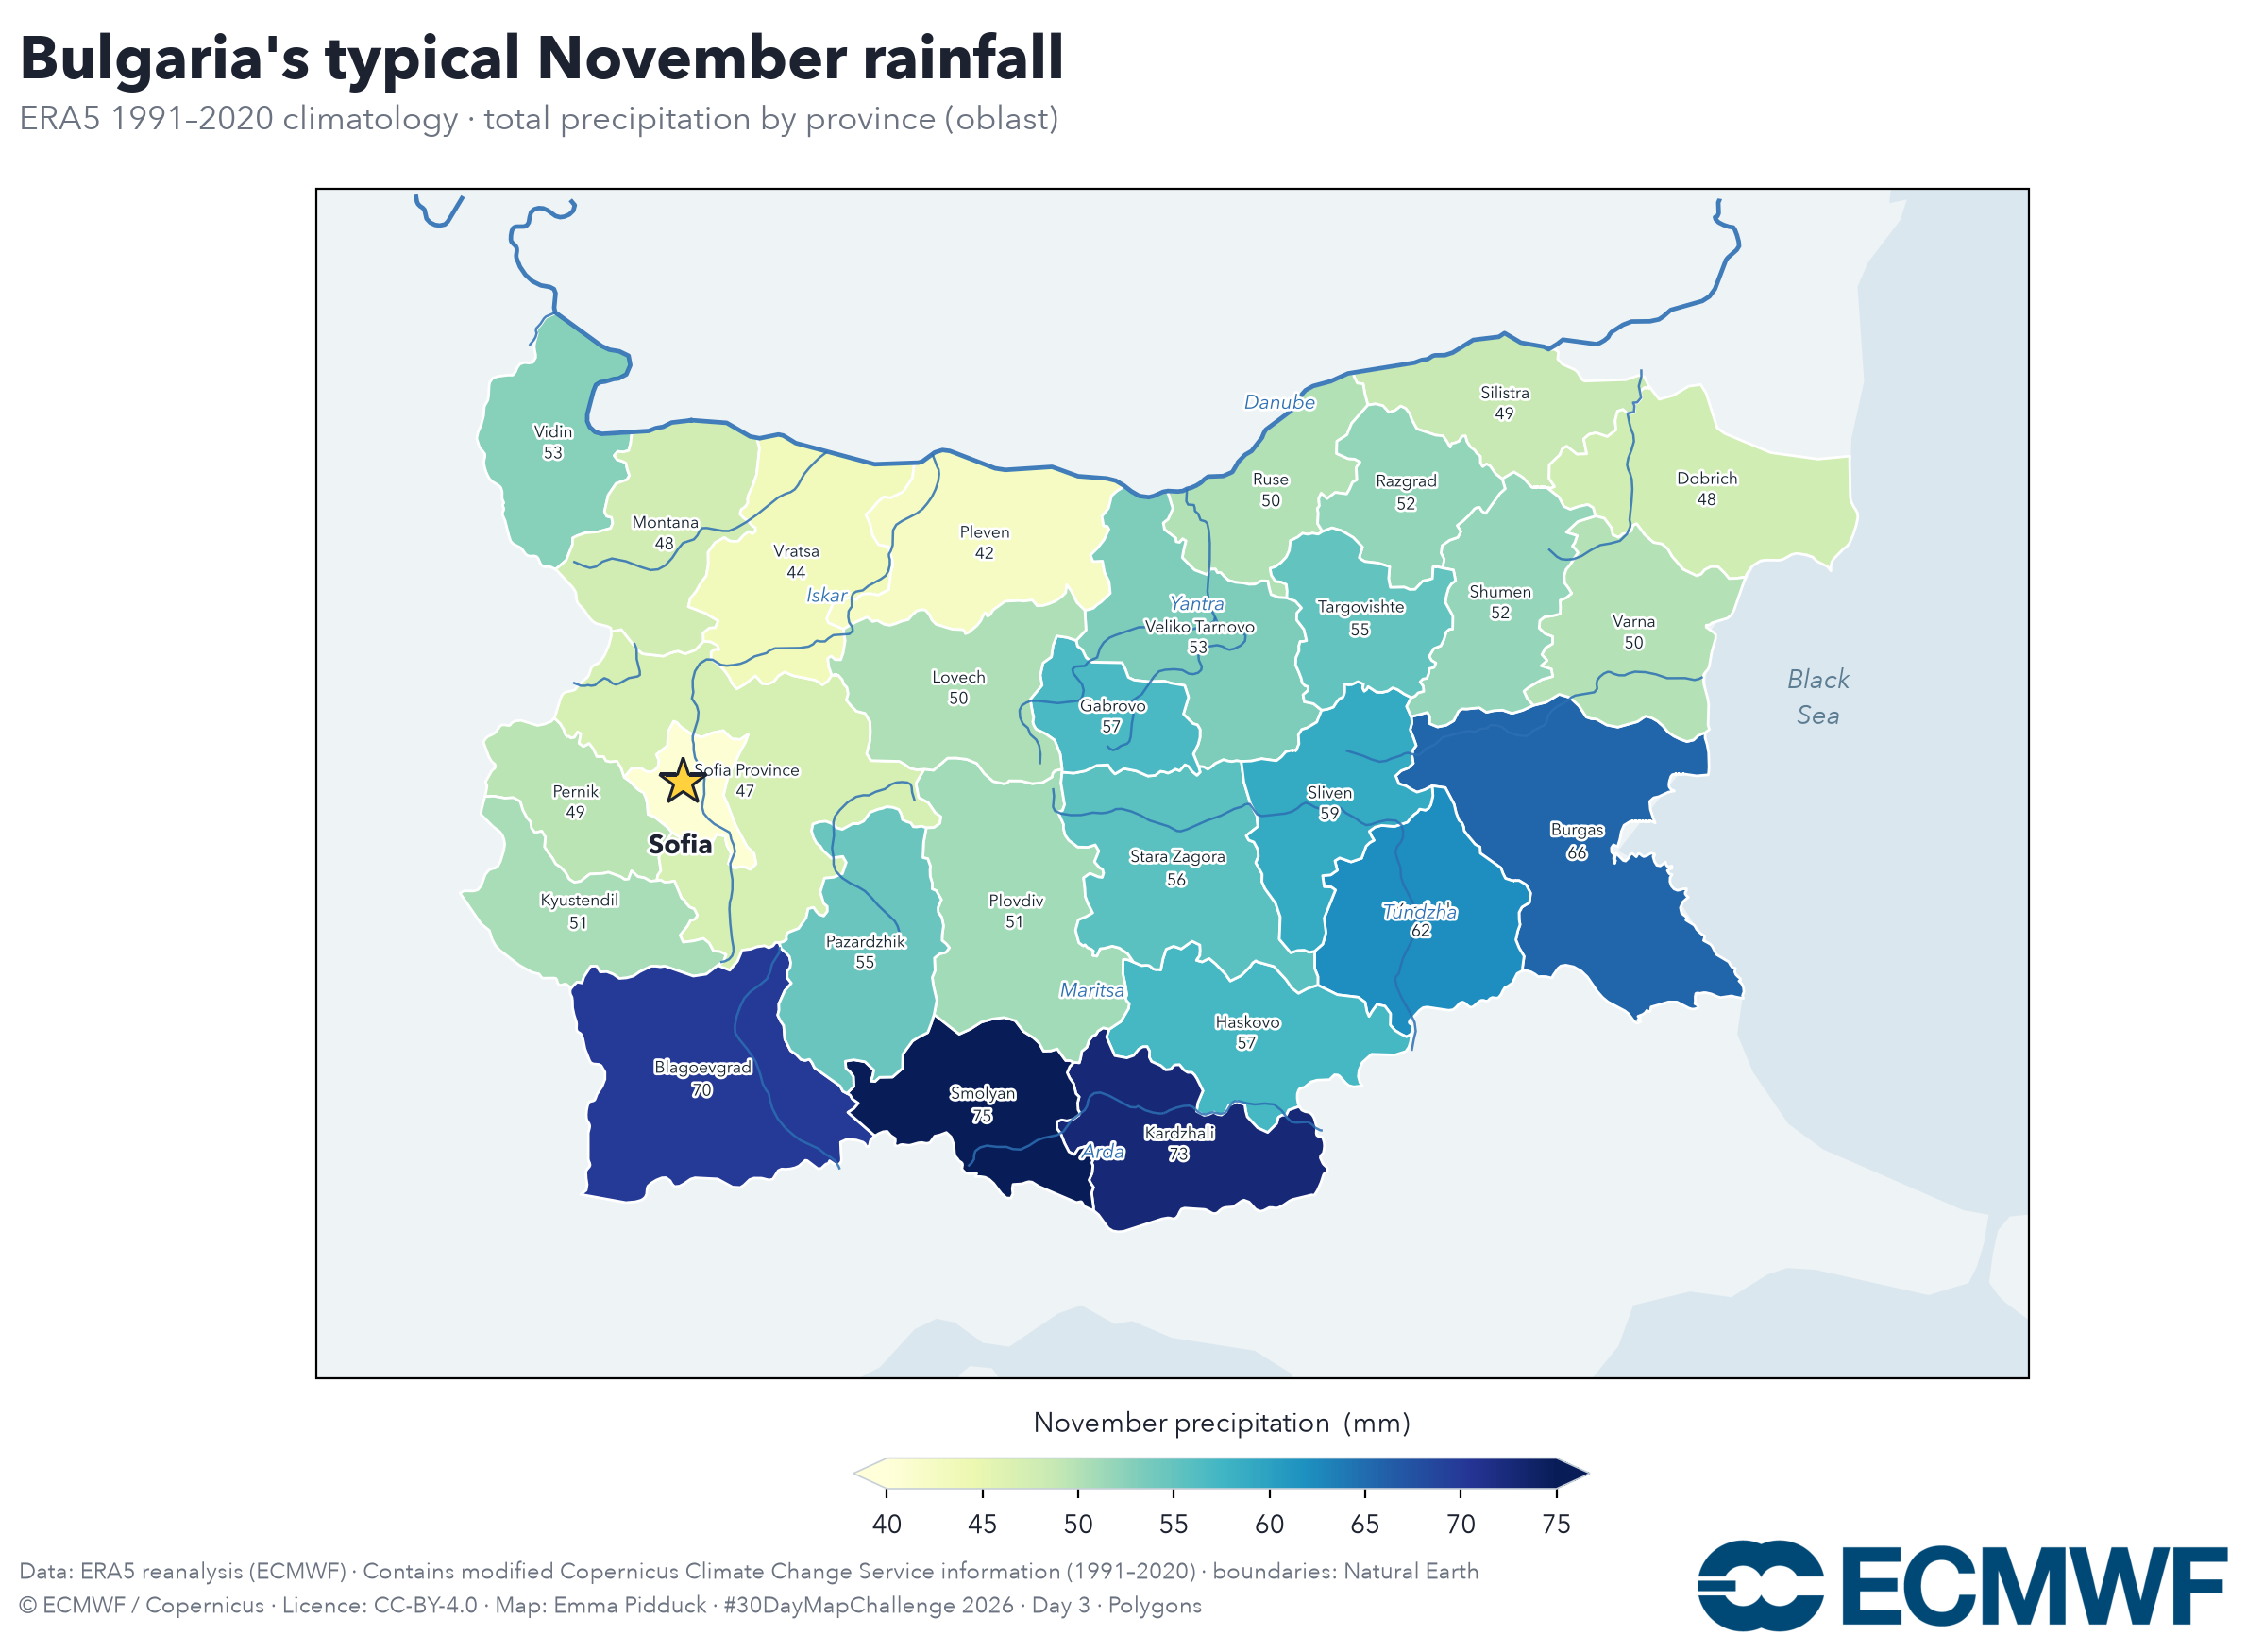

In [6]:
P_arr = np.array(list(P.values()))
vmin, vmax = np.floor(P_arr.min()/5)*5, np.ceil(P_arr.max()/5)*5
norm = Normalize(vmin, vmax); cmap = plt.get_cmap("YlGnBu")
fig = plt.figure(figsize=(13, 9.0), dpi=200); fig.patch.set_facecolor("#fff")
ax = fig.add_axes([0.03, 0.17, 0.94, 0.70], projection=proj)
for nm, g in provinces:
    ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor=cmap(norm(P[nm])), edgecolor="#fff", linewidth=1.0, zorder=2)
draw_geo(ax)
for nm, g in provinces:
    lab = province_label(nm)
    if lab is None: continue
    c = g.centroid
    ax.text(c.x, c.y, f"{lab}\n{P[nm]:.0f}", transform=ccrs.PlateCarree(), ha="center", va="center",
            fontsize=6.3, color="#11202b", zorder=6, path_effects=halo, linespacing=0.95)
fig.text(0.03, 0.935, "Bulgaria's typical November rainfall", color=INK, fontsize=23, fontweight="bold")
fig.text(0.03, 0.905, "ERA5 1991–2020 climatology · total precipitation by province (oblast)", color=MUT, fontsize=12.5)
cax = fig.add_axes([0.37, 0.105, 0.30, 0.018])
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", extend="both")
cb.set_label("November precipitation  (mm)", color=INK, fontsize=10.5, labelpad=10); cb.ax.xaxis.set_label_position("top")
plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK); cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)
add_footer(fig); add_logo(fig)
fig.savefig("day03_polygons_rain.png", facecolor="#fff", bbox_inches="tight"); plt.show()

## Map 2 — the bivariate: rainfall × temperature

Two variables at once. Each province is placed in a tercile of rainfall **and** a tercile of
temperature; the 3×3 key blends the two. The cold, wet southern mountains (where November is
already turning to snow) read dark blue; the mild, drier lowlands run teal to grey.

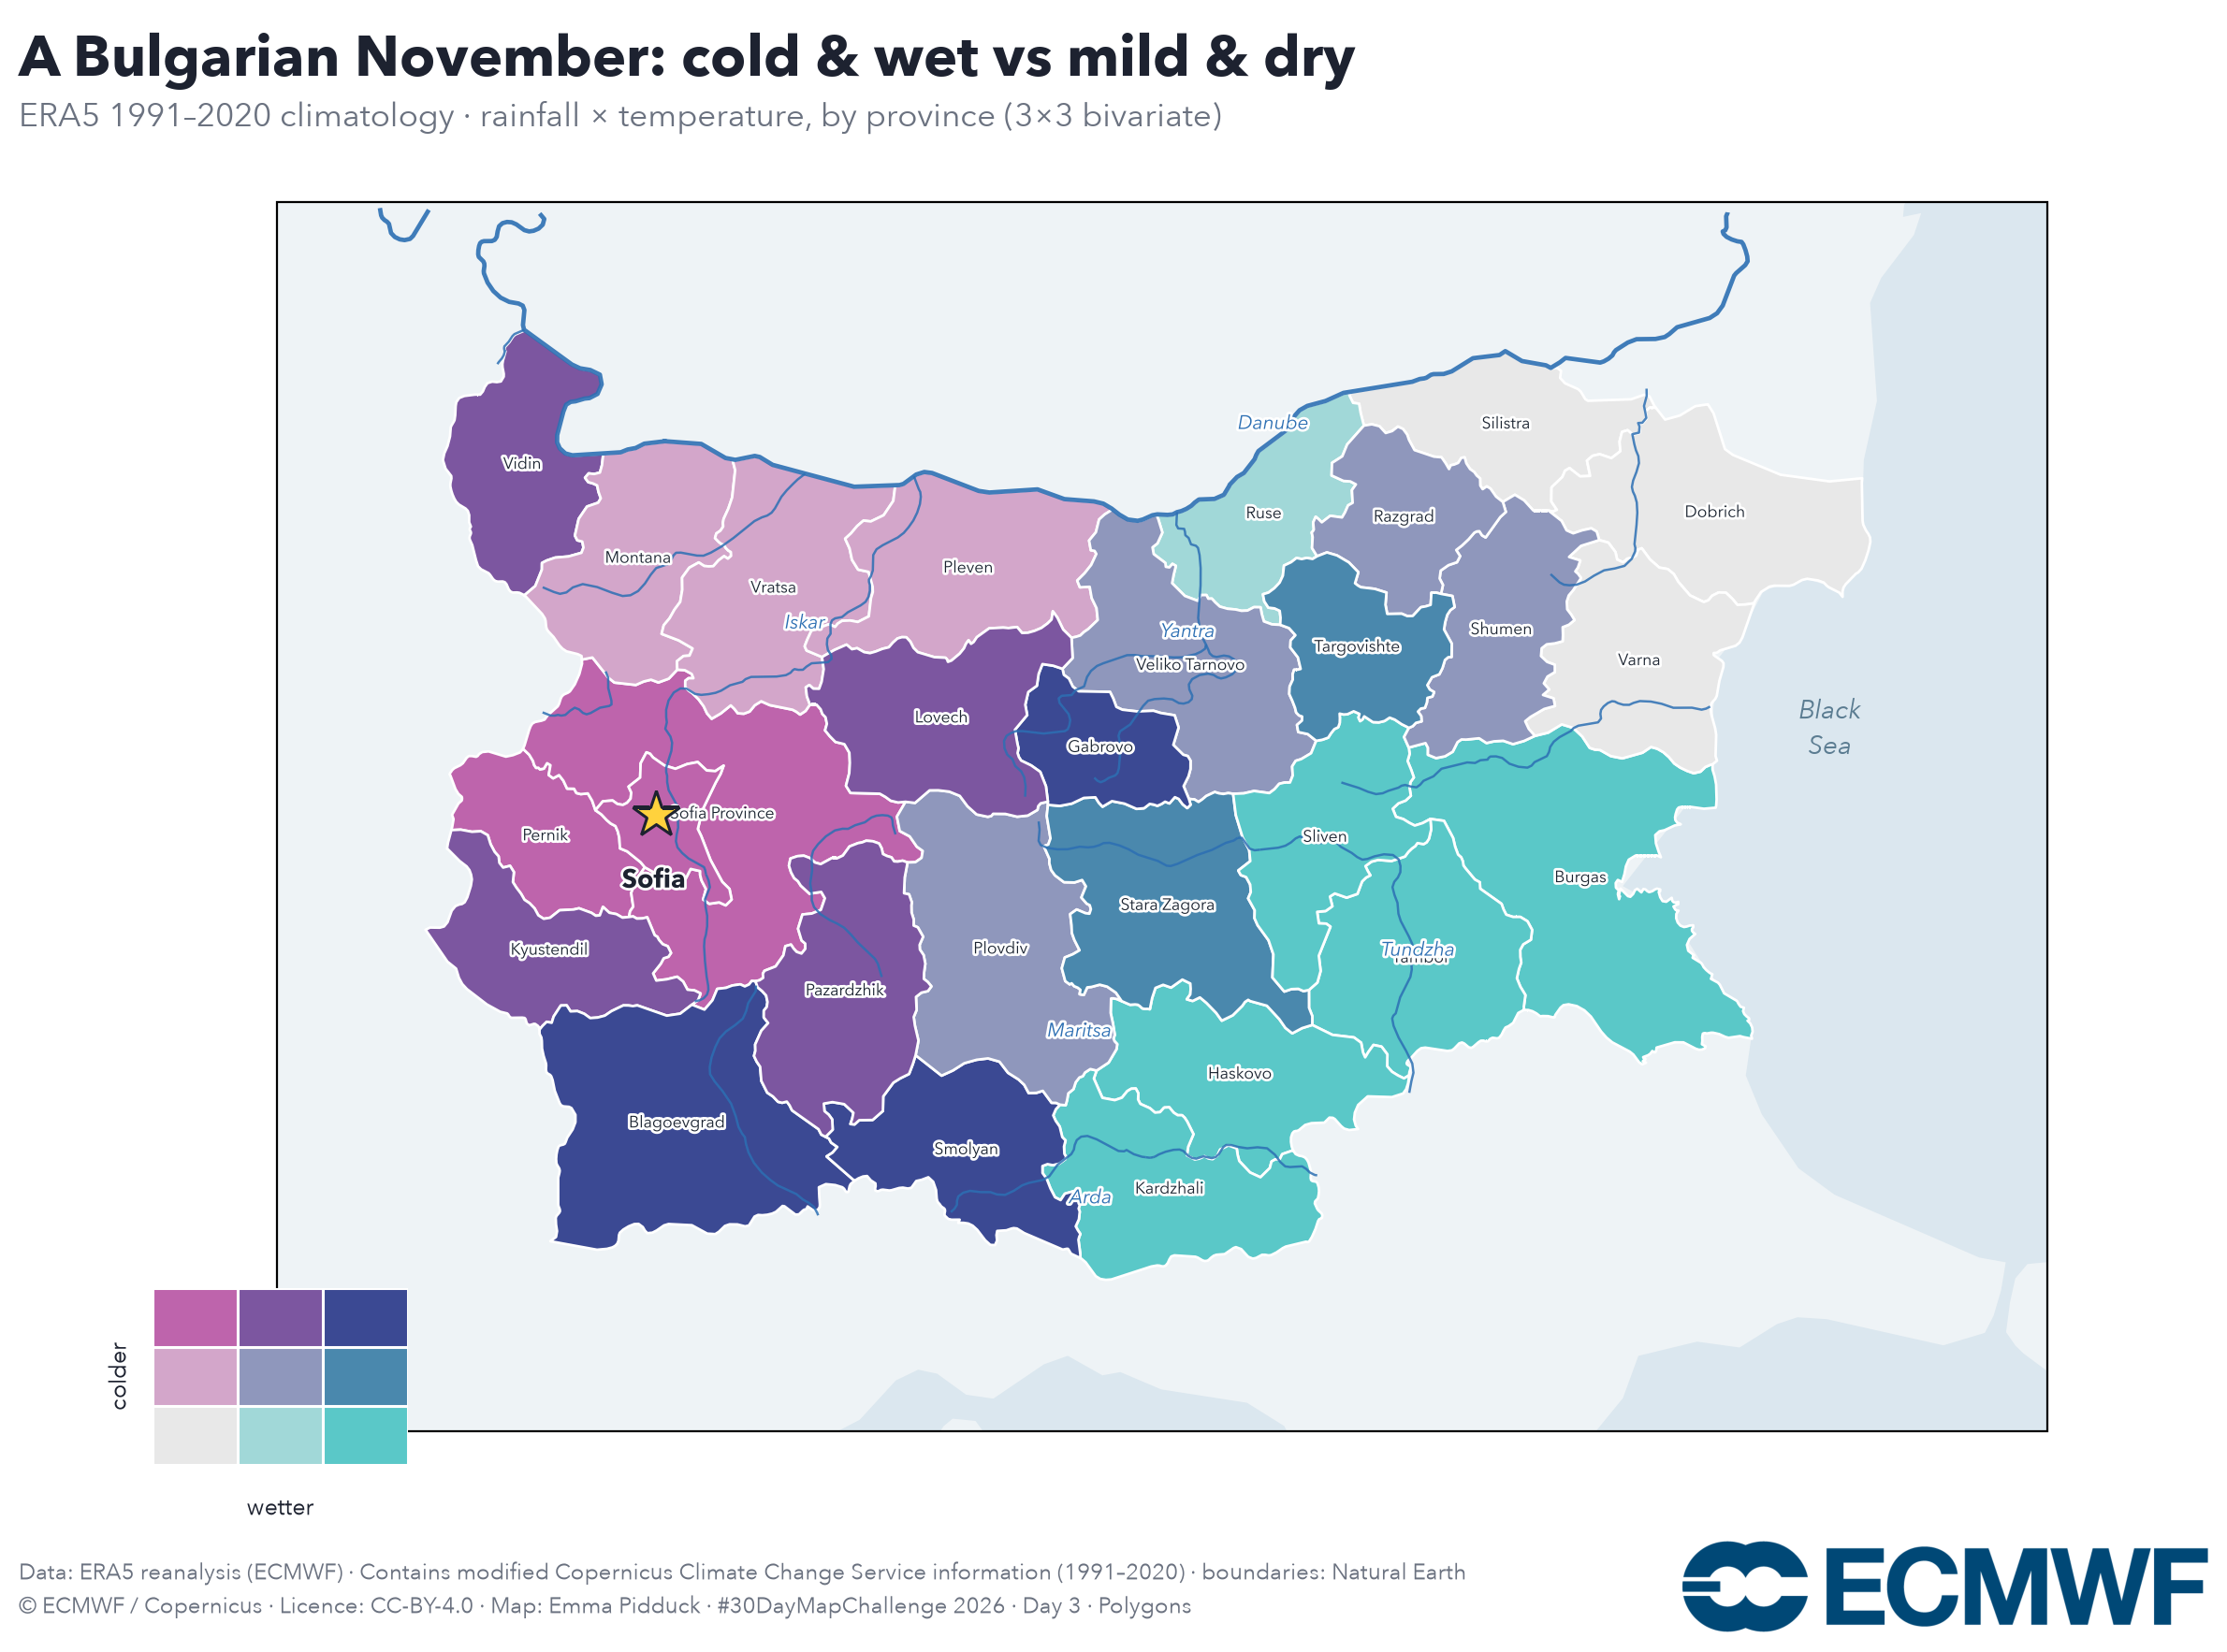

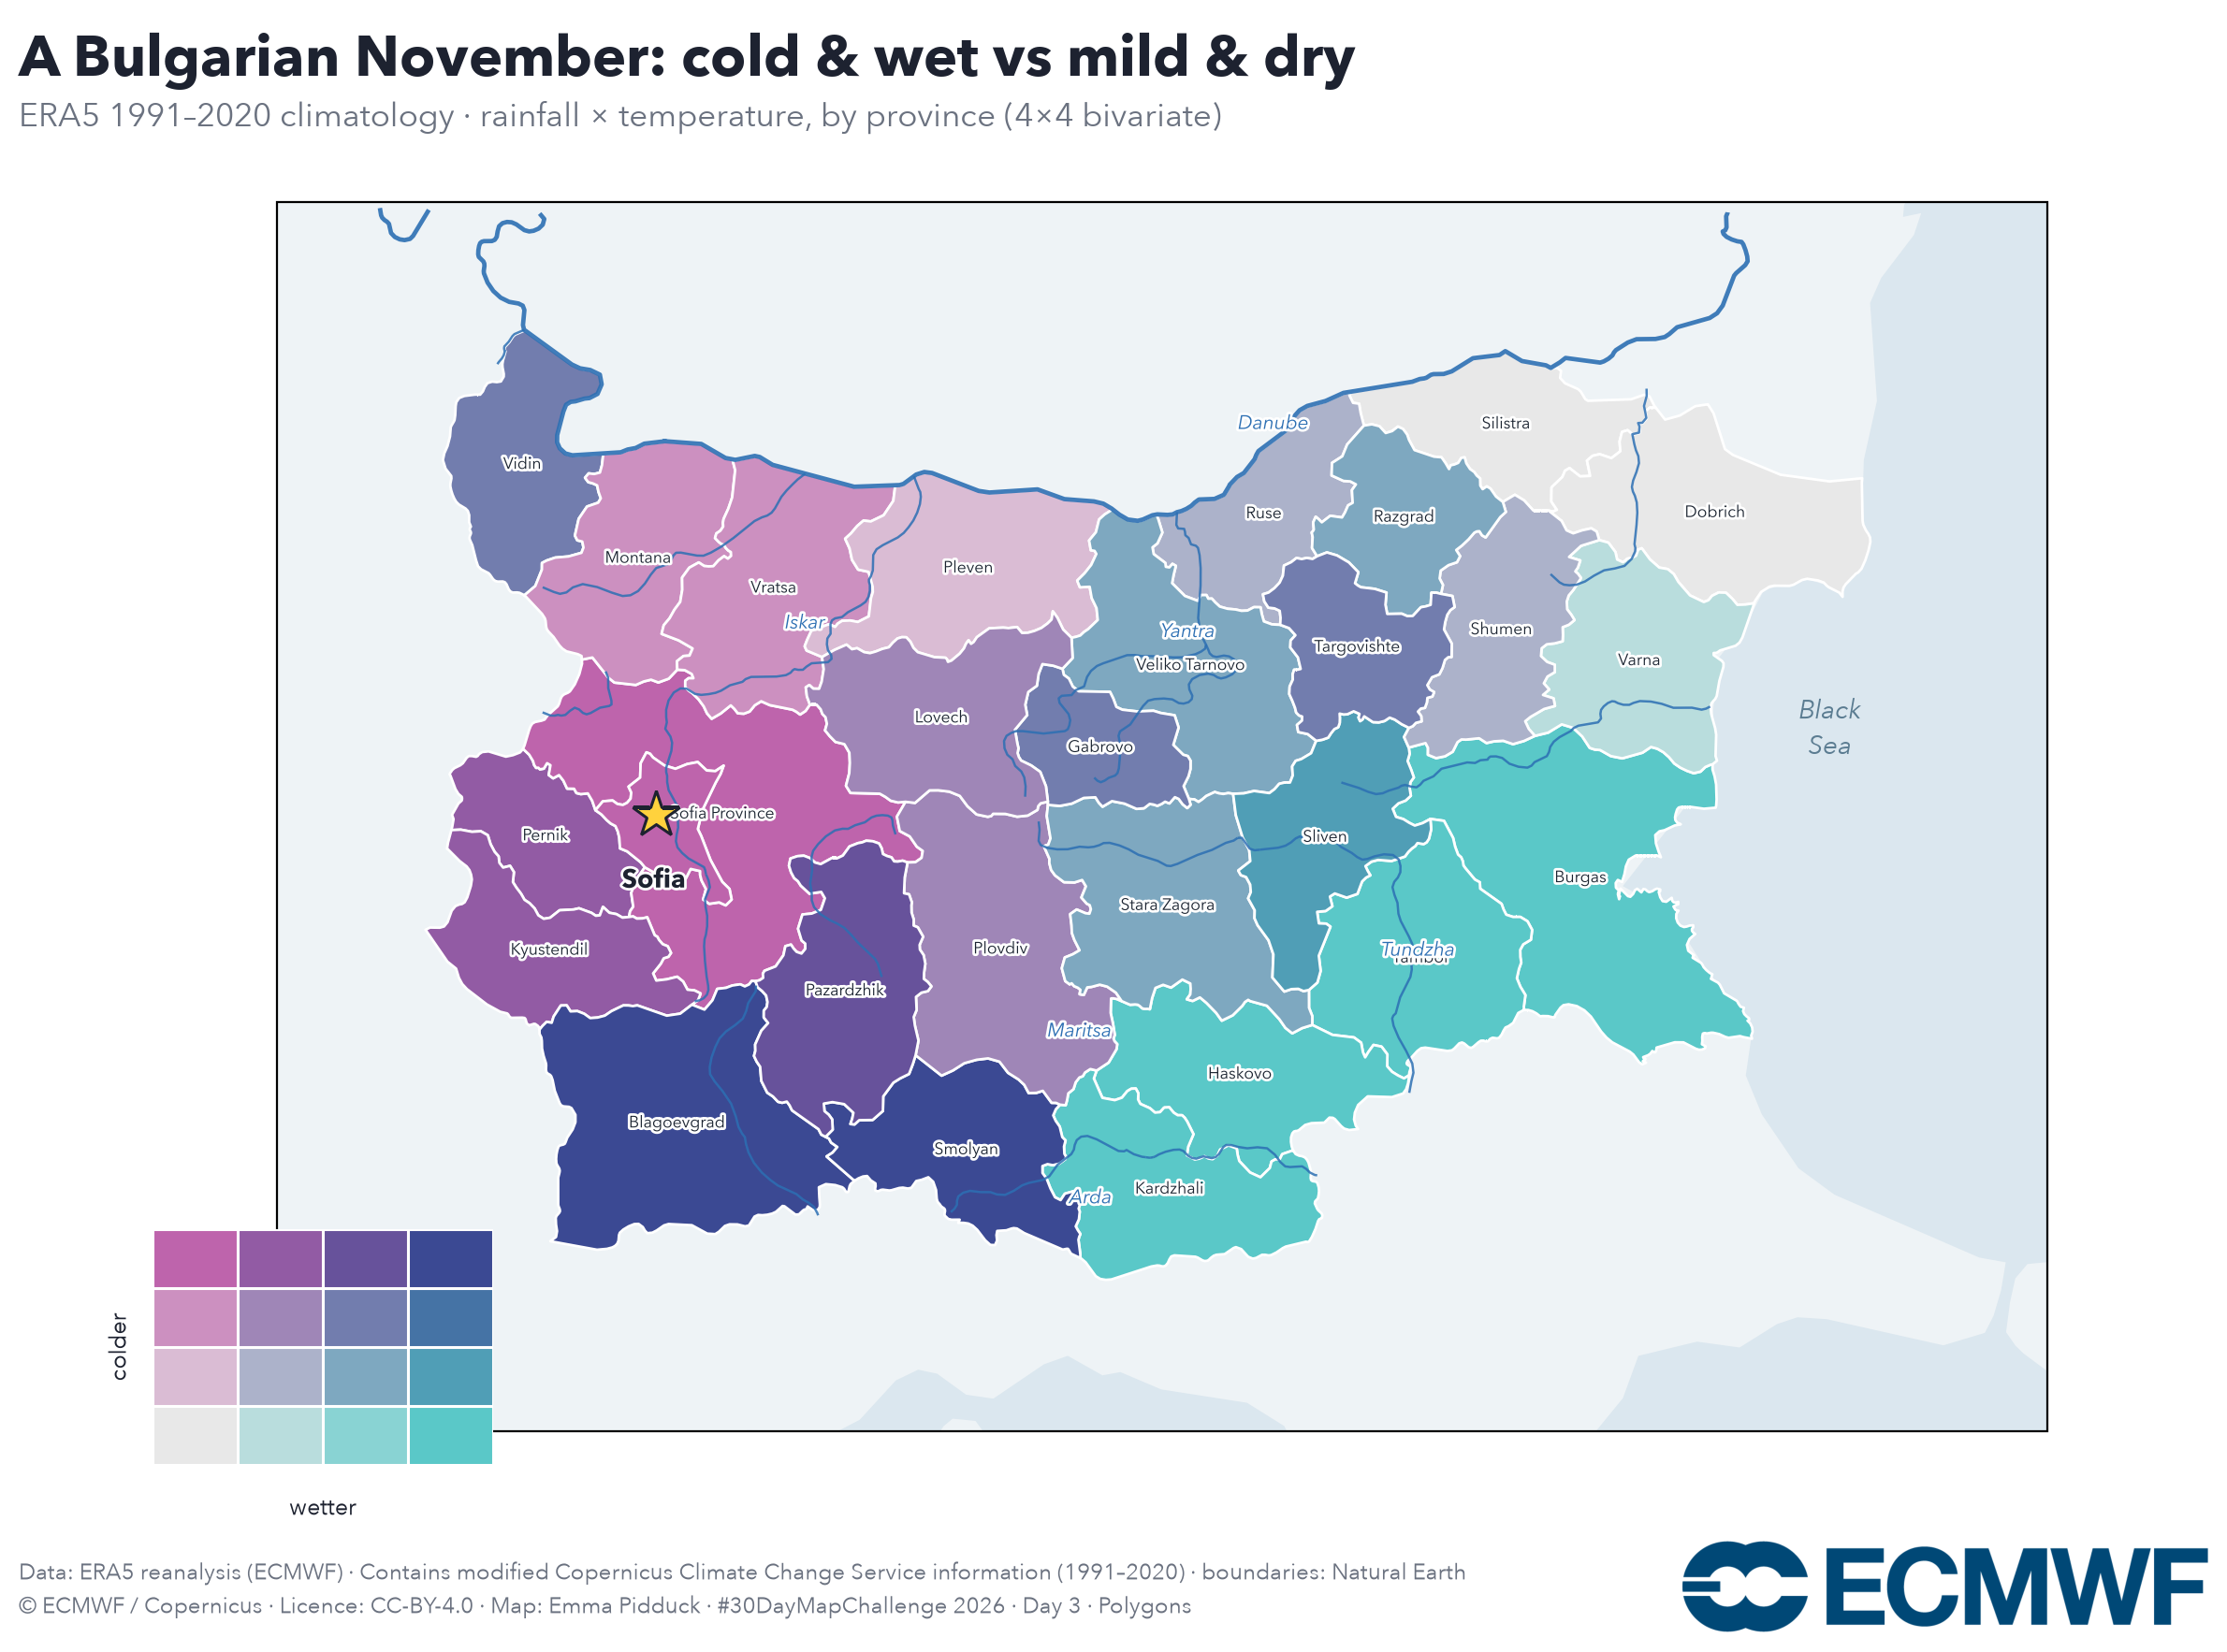

In [7]:
def bil(fx, fy):
    c = np.array([[0.909,0.909,0.909],[0.353,0.784,0.784],[0.745,0.392,0.675],[0.231,0.286,0.576]])
    top = c[0]*(1-fx) + c[1]*fx; bot = c[2]*(1-fx) + c[3]*fx
    return tuple(top*(1-fy) + bot*fy)

def bivariate(N, fname, show=True):
    names = [nm for nm, _ in provinces]
    Pv = np.array([P[nm] for nm in names]); Tv = np.array([T[nm] for nm in names])
    pcut = np.quantile(Pv, [k/N for k in range(1, N)]); tcut = np.quantile(-Tv, [k/N for k in range(1, N)])
    pi = np.digitize(Pv, pcut); ti = np.digitize(-Tv, tcut)
    fig = plt.figure(figsize=(13, 9.0), dpi=200); fig.patch.set_facecolor("#fff")
    ax = fig.add_axes([0.03, 0.14, 0.94, 0.73], projection=proj)
    for k, (nm, g) in enumerate(provinces):
        ax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor=bil(pi[k]/(N-1), ti[k]/(N-1)), edgecolor="#fff", linewidth=1.0, zorder=2)
    draw_geo(ax)
    for nm, g in provinces:
        lab = province_label(nm)
        if lab is None: continue
        c = g.centroid
        ax.text(c.x, c.y, lab, transform=ccrs.PlateCarree(), ha="center", va="center", fontsize=6.3, color="#1a2330", zorder=6, path_effects=halo)
    fig.text(0.03, 0.945, "A Bulgarian November: cold & wet vs mild & dry", color=INK, fontsize=22, fontweight="bold")
    fig.text(0.03, 0.915, f"ERA5 1991–2020 climatology · rainfall × temperature, by province ({N}×{N} bivariate)", color=MUT, fontsize=12.5)
    sz = 0.035; lax = fig.add_axes([0.085, 0.12, sz*N, sz*N]); lax.set_xlim(0, N); lax.set_ylim(0, N); lax.axis("off")
    for i in range(N):
        for j in range(N):
            lax.add_patch(plt.Rectangle((i, j), 1, 1, facecolor=bil(i/(N-1), j/(N-1)), edgecolor="white", linewidth=1.1))
    lax.annotate("", xy=(N+0.15, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.3))
    lax.annotate("", xy=(0, N+0.15), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.3))
    lax.text(N/2, -0.45, "wetter", ha="center", va="top", fontsize=9, color=INK)
    lax.text(-0.4, N/2, "colder", ha="center", va="center", rotation=90, fontsize=9, color=INK)
    add_footer(fig); add_logo(fig)
    fig.savefig(fname, facecolor="#fff", bbox_inches="tight")
    plt.show() if show else plt.close()

bivariate(3, "day03_polygons_bivariate.png")        # the one for posting
bivariate(4, "day03_polygons_bivariate_4x4.png")    # finer-gradient bonus

## Note

This notebook streams **30 years** of ERA5 from the cloud, so a live run takes a few minutes — not
the one-second pull of a single field. The figures are saved as `day03_polygons_rain.png` and
`day03_polygons_bivariate.png` (plus a 4×4 bonus), ready to post.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*